<small>📌 <b>먼저 내 노트로 저장하기</b></small><br><small>이 노트는 내 구글 드라이브의 『Colab Notebooks』 폴더(자동 사본으로 만들었으면 『배화 Colab 실습』 폴더)에 저장돼요.</small><br><small>사이트의 「▶ 내 Colab 노트 만들기」로 열었으면 사본·공유가 이미 돼 있어요 — 아래 ①~④ 는 건너뛰어도 돼요.</small><br><br><small>① 맨 위 <b>파일 → Drive에 사본 저장</b> (안 하면 쓴 게 사라져요)</small><br><img src="https://baehwa-ai-2026.web.app/aisocial/img/colab_step_copy.jpg" width="300"><br><br><small>② 사본이 열리면 오른쪽 위 <b>공유</b> 단추를 눌러요.</small><br><img src="https://baehwa-ai-2026.web.app/aisocial/img/colab_step_share.jpg" width="300"><br><br><small>③ 일반 액세스에서 <b>「링크가 있는 모든 사용자」</b>를 고른 다음 <b>링크 복사</b>.</small><br><img src="https://baehwa-ai-2026.web.app/aisocial/img/colab_step_anyone.jpg" width="300"><br><br><small>④ 사이트로 돌아와 <b>『📓 내 Colab 실습 노트』</b> 칸에 붙여넣고 <b>『보관』</b>을 눌러요 — <b>『✅ 보관됨』</b>이 뜨면 선생님께 간 거예요.</small><br><img src="https://baehwa-ai-2026.web.app/aisocial/img/colab_step_paste.jpg" width="300">

<small>☁ <b>저장 확인</b> — 맨 위 노트 이름 옆에 <b>체크된 구름</b>이 보이면 내 드라이브에 <b>실시간으로 저장</b>되고 있어요. (구름이 없고 「Drive로 복사」가 보이면 아직 내 노트가 아니에요 — 파일 → Drive에 사본 저장)</small><br>

![체크된 구름 = 저장 잘 되는 중](https://raw.githubusercontent.com/SoojiNoh/baehwa-colab/main/nb/img/colab_saved.png)

# 📱 문자 메시지 스팸 가려내기 (심화) — 머신러닝

UCI SMS Spam Collection(캐글 uciml/sms-spam-collection-dataset) · 캐글 Code 득표 상위 흐름(TF-IDF + 나이브 베이즈)을 고등학생 수준으로 줄였어요.

- (심화) 노트예요: 빈칸 없이 끝까지 돌아가요. 한 칸씩 실행하며 숫자와 그래프를 읽고, 보고서 「1-1·1-2·1-3」에 써요.

In [1]:
# 0. 준비 — 그대로 실행해요
!pip -q install koreanize-matplotlib   # 한글 그래프 글꼴
import koreanize_matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 1. 데이터 불러오기 — read_csv 로 바로

In [2]:
df = pd.read_csv('https://baehwa-ai-2026.web.app/dataproject/csv/kaggle/spam.csv', encoding='latin-1')[['v1', 'v2']]
df.columns = ['정답', '문자']
print(df.shape)
df.head()

(5572, 2)
     정답                                                                                                                                                           문자
0   ham                                              Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
1   ham                                                                                                                                Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
3   ham                                                                                                            U dun say so early hor... U c already then say...
4   ham                                                                                                Nah I don't think he goes to usf, he lives around here though


## 2. EDA — 모델 힌트가 되는 것만
스팸은 13% 정도로 적어요(불균형) → 정확도만 보지 말고 **F1** 도 봐요. 스팸이 더 길어요 → 길이도 좋은 단서.

정답
ham     0.866
spam    0.134
Name: proportion, dtype: float64


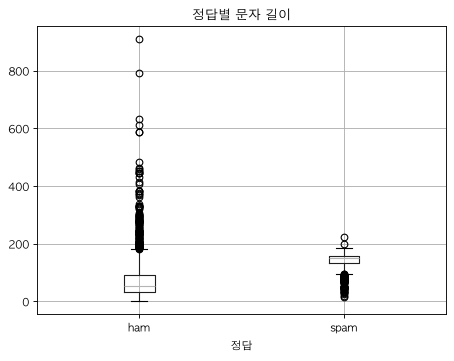

In [3]:
print(df['정답'].value_counts(normalize=True).round(3))
df['길이'] = df['문자'].str.len()
df.boxplot(column='길이', by='정답'); plt.suptitle(''); plt.title('정답별 문자 길이'); plt.show()

## 3. 글 → 숫자 (TF-IDF)
낱말이 그 문자에 얼마나 특별하게 나오는지를 점수로 바꿔요.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
X_train, X_test, y_train, y_test = train_test_split(df['문자'], df['정답'], test_size=0.2, random_state=0, stratify=df['정답'])
vec = TfidfVectorizer(stop_words='english', min_df=2)
Xtr = vec.fit_transform(X_train); Xte = vec.transform(X_test)
print('낱말 수', Xtr.shape[1])

낱말 수 3361


## 4. 모델 학습 — 나이브 베이즈

In [5]:
from sklearn.naive_bayes import MultinomialNB
model = MultinomialNB(alpha=0.1)
model.fit(Xtr, y_train)
pred = model.predict(Xte)

## 5. 성능평가 — 정확도·정밀도·재현율·F1·혼동행렬

정확도 0.977
스팸 F1 0.91
              precision    recall  f1-score   support

         ham      0.982     0.992     0.987       966
        spam      0.942     0.879     0.910       149

    accuracy                          0.977      1115
   macro avg      0.962     0.935     0.948      1115
weighted avg      0.976     0.977     0.976      1115



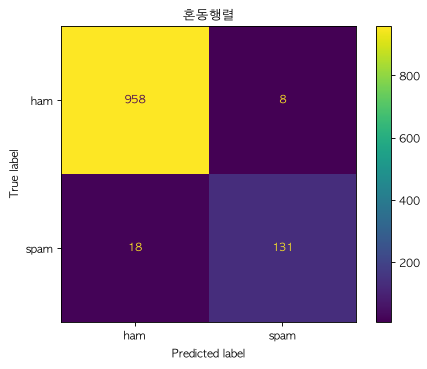

In [6]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
print('정확도', round(accuracy_score(y_test, pred), 3))
print('스팸 F1', round(f1_score(y_test, pred, pos_label='spam'), 3))
print(classification_report(y_test, pred, digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, pred); plt.title('혼동행렬'); plt.show()

## 6. 생각해 보기
- 정상 문자를 스팸으로 잘못 거르는 것(거짓 양성)과 스팸을 놓치는 것 중 무엇이 더 나쁠까요? → 보고서 「1-3 한계」